# Trabajo Práctico 2 (TP2) - Parte 2: Regresión Logística, Curva de Aprendizaje y Evaluación de Desempeño

### Machine Learning 1 (23433)
#### Facultad de Ingeniería - Universidad Nacional de Asunción (FIUNA)

---

## Objetivos de la Parte 2
1. Configurar una partición estratificada Train/Test (80% Train, 20% Test sobre 64,295 muestras) previniendo el fuga de datos (*data leakage*).
2. Diseñar un `ColumnTransformer` profesional con `SimpleImputer`, `PolynomialFeatures(degree=2)`, `StandardScaler` y `OneHotEncoder`.
3. Entrenar un modelo de `LogisticRegression(class_weight='balanced')` con optimización de hiperparámetros vía `GridSearchCV`.
4. Calcular y graficar la **Curva de Aprendizaje (`learning_curve`)** evaluando la convergencia en validación cruzada.
5. Optimizar el umbral de decisión ($	au^*$) e inspeccionar la Matriz de Confusión, Curva ROC (AUC) y Curva Precision-Recall.


In [1]:
# 1. Carga de Librerías y Dataset del TP2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Carga del Dataset del TP2
csv_path = 'reglamento_nuevo_unificado.csv'
df_raw = pd.read_csv(csv_path)
print(f"Dataset del TP2 cargado exitosamente: {df_raw.shape[0]:,} filas.")


Dataset del TP2 cargado exitosamente: 64,295 filas.


In [2]:
career_code_mapping = {
    # === ESCRIBE TU CÓDIGO AQUÍ ===
    'CIV-PLS13': 'Ing. Civil', 'CIV-PLS23': 'Ing. Civil', 'INT9CONSTR': 'Ing. Civil',
    'INT9TRANSP': 'Ing. Civil', 'INT9ORTERR': 'Ing. Civil', 'INT9SANEHI': 'Ing. Civil',
    
    'ELE-PLS13': 'Ing. Electromecánica', 'ELE-PLS23': 'Ing. Electromecánica',
    'INT9ELECTR': 'Ing. Electromecánica', 'INT9SDIGYT': 'Ing. Electromecánica',
    
    'MCT-PLS13': 'Ing. Mecatrónica', 'MCT-PLS23': 'Ing. Mecatrónica', 'MCT9-OPT': 'Ing. Mecatrónica',
    
    'IND-PLS13': 'Ing. Industrial', 'IND-PLS23': 'Ing. Industrial',
    'INT9G-ECO': 'Ing. Industrial', 'INT9-PROYT': 'Ing. Industrial',
    
    'CGF-PLS13': 'Ing. Geográfica', 'CGF-PLS23': 'Ing. Geográfica', 'INT9RNYMA': 'Ing. Geográfica',
    
    'MEC-PLS13': 'Ing. Mecánica', 'MEC-PLS23': 'Ing. Mecánica',
    'INT9MECANI': 'Ing. Mecánica', 'MEC9-OPT': 'Ing. Mecánica',
    
    'ECA-PLS13': 'Ing. Electrónica', 'ECA-PLS23': 'Ing. Electrónica', 'ECA9-OPT': 'Ing. Electrónica'
}

df_clean = df_raw.copy()

df_clean['Carrera_Nombre'] = (df_clean['Cod.Car.Sec'].astype(str).str.strip().map(career_code_mapping))

df_clean['Target'] = (df_clean['Aprobado'] == 'S').astype(int)

df_clean['Primer_Par_Clean'] = pd.to_numeric(df_clean['Primer.Par'], errors='coerce')

df_clean['Segundo_Par_Clean'] = pd.to_numeric(df_clean['Segundo.Par'], errors='coerce')

df_clean['Score_Parciales'] = (df_clean['Primer_Par_Clean'].fillna(0) + df_clean['Segundo_Par_Clean'].fillna(0)) / 2

df_clean['Diff_Parciales'] = (df_clean['Segundo_Par_Clean'].fillna(0) - df_clean['Primer_Par_Clean'].fillna(0))

df_clean['TPLab_Clean'] = pd.to_numeric(df_clean['TPLab.'], errors='coerce')

df_clean['Firma_Clean'] = pd.to_numeric(df_clean['Firma'], errors='coerce')

df_clean['FirmaCalc_Clean'] = pd.to_numeric(df_clean['FirmaCalculada'], errors='coerce')

df_clean['Asis_Clean'] = pd.to_numeric(df_clean['Asis'], errors='coerce')

print(df_clean.shape)

(64295, 39)


## Ejercicio 1: Partición Estratificada Train / Test

Define las listas de atributos numéricos `num_features` y categóricos `cat_features`.
Realiza una partición estratificada del 80% para entrenamiento (`X_train`) y 20% para prueba (`X_test`).


In [3]:
# TODO: Definir num_features, cat_features y particionar X e y
# === ESCRIBE TU CÓDIGO AQUÍ ===
num_features = ['Primer_Par_Clean', 'Segundo_Par_Clean', 'Score_Parciales', 'Diff_Parciales', 'TPLab_Clean', 'Firma_Clean', 'FirmaCalc_Clean', 'Asis_Clean']
cat_features = ['Carrera_Nombre', 'Semestre']

X = df_clean[num_features + cat_features]
y = df_clean['Target']

# Suponiendo df_clean cargado del notebook anterior
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDistribución Target completa:")
print(y.value_counts(normalize=True))

print("\nDistribución Target entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución Target test:")
print(y_test.value_counts(normalize=True))

X_train: (51436, 10)
X_test: (12859, 10)

Distribución Target completa:
Target
1    0.606657
0    0.393343
Name: proportion, dtype: float64

Distribución Target entrenamiento:
Target
1    0.606657
0    0.393343
Name: proportion, dtype: float64

Distribución Target test:
Target
1    0.606657
0    0.393343
Name: proportion, dtype: float64


## Ejercicio 2: Construcción del Preprocesador Profesional (`ColumnTransformer`)

Construye un `Pipeline` numérico con:
1. `SimpleImputer(strategy='median')`
2. `PolynomialFeatures(degree=2, include_bias=False)`
3. `StandardScaler()`

Y un `Pipeline` categórico con `SimpleImputer` y `OneHotEncoder(handle_unknown='ignore')`.


In [4]:
# TODO: Ensamblar num_transformer, cat_transformer y preprocessor
# === ESCRIBE TU CÓDIGO AQUÍ ===
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## Ejercicio 3: Entrenamiento del Modelo y Búsqueda en Malla (`GridSearchCV`)

Ensambla `full_pipeline` con `LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=2000)`.
Configura `GridSearchCV` sobre el parámetro de regularización `C` en `[0.01, 0.1, 1.0, 10.0]` con `scoring='f1'`.


In [5]:
# TODO: Instanciar full_pipeline y GridSearchCV
# === ESCRIBE TU CÓDIGO AQUÍ ===

# Modelo de regresion logistica
log_reg = LogisticRegression(
    class_weight='balanced',
    solver='lbfgs',
    max_iter=2000,
    random_state=42
)
# Pipeline completo: preprocesamiento + modelo
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', log_reg)
])
# Valores de C a probar
param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0]
}
# Validacion cruzada estratificada 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# Busqueda del mejor valor de C
grid_search = GridSearchCV(
    estimator=full_pipeline, 
    param_grid=param_grid, 
    cv=cv, 
    scoring='f1', 
    n_jobs=1
)
# Entrenamiento
grid_search.fit(X_train, y_train)

print(f"Mejor C: {grid_search.best_params_}")
print(f"Mejor F1 promedio en validacion: {grid_search.best_score_}")

best_model = grid_search.best_estimator_

Mejor C: {'classifier__C': 0.1}
Mejor F1 promedio en validacion: 0.8838634353081378


## Ejercicio 4: Graficación de la Curva de Aprendizaje (`learning_curve`)

Calcula y grafica la curva de aprendizaje utilizando `learning_curve` sobre `X_train` y `y_train` con 10 tamaños de entrenamiento (`np.linspace(0.1, 1.0, 10)`).


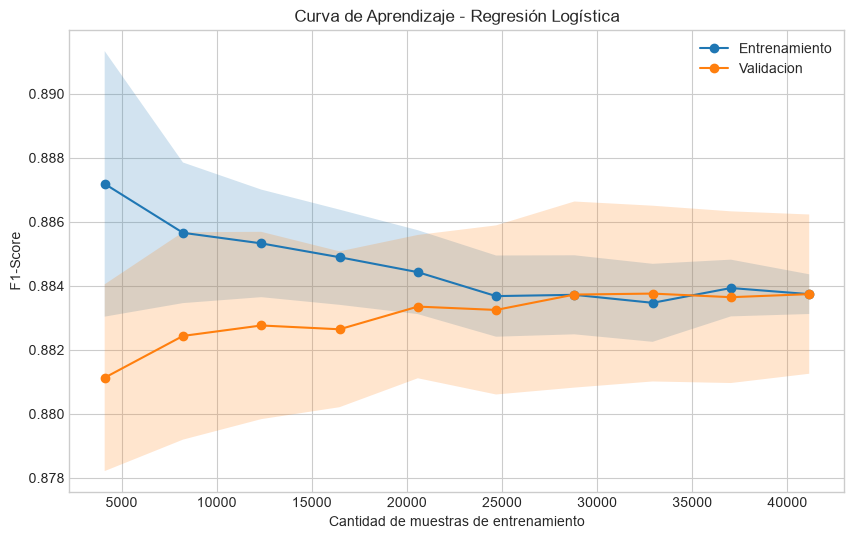

In [6]:
# TODO: Calcular y graficar la Curva de Aprendizaje (Learning Curve)
# === ESCRIBE TU CÓDIGO AQUÍ ===

# Curva de aprendizaje
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_model, 
    X=X_train, 
    y=y_train, 
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1', 
    train_sizes=np.linspace(0.1, 1.0, 10), 
    n_jobs=1
)

# Promedio y desviacion estandar de los 5 folds
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

# Grafico
plt.figure(figsize=(10,6))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Entrenamiento'
)

plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validacion'
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

plt.xlabel('Cantidad de muestras de entrenamiento')
plt.ylabel('F1-Score')
plt.title('Curva de Aprendizaje - Regresión Logística')
plt.legend()
plt.grid(True)
plt.show()

## Ejercicio 5: Optimización del Umbral de Decisión y Evaluación de Desempeño

En el conjunto de prueba (`X_test`):
1. Obtén las probabilidades de aprobación `y_proba_test`.
2. Optimiza el umbral de decisión ($	au^*$) entre `0.1` y `0.9` que maximiza el F1-Score.
3. Grafica la **Matriz de Confusión**, la **Curva ROC (AUC)** y la **Curva Precision-Recall**.


In [7]:
# TODO: Optimizar umbral y graficar métricas en Test
# === ESCRIBE TU CÓDIGO AQUÍ ===

# 1. Obtener probabilidades de aprobacion en Test
y_proba_test = best_model.predict_proba(X_test)[:, 1]

# 2. Buscar el mejor umbral entre 0.1 y 0.9
thresholds = np.arange(0.1, 0.91, 0.01)

f1_scores = []

for threshold in thresholds:
    y_pred_temp = (y_proba_test >= threshold).astype(int)
    score = f1_score(y_test, y_pred_temp)
    f1_scores.append(score)

# Indice del mejor F1
best_idx = np.argmax(f1_scores)

best_thresh = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Mejor umbral: {best_thresh:.2f}")
print(f"Mejor F1 en Test: {best_f1:.4f}")

y_pred = (y_proba_test >= best_thresh).astype(int)


print("\nMétricas con umbral optimizado:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Mejor umbral: 0.41
Mejor F1 en Test: 0.8882

Métricas con umbral optimizado:
Accuracy : 0.8597
Precision: 0.8598
Recall   : 0.9185
F1-Score : 0.8882

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.77      0.81      5058
           1       0.86      0.92      0.89      7801

    accuracy                           0.86     12859
   macro avg       0.86      0.84      0.85     12859
weighted avg       0.86      0.86      0.86     12859



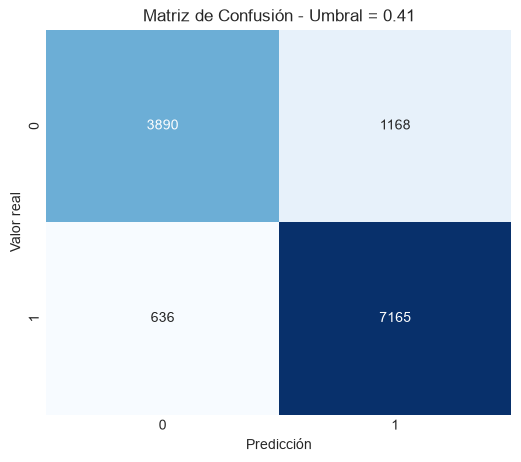

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title(f'Matriz de Confusión - Umbral = {best_thresh:.2f}')

plt.show()

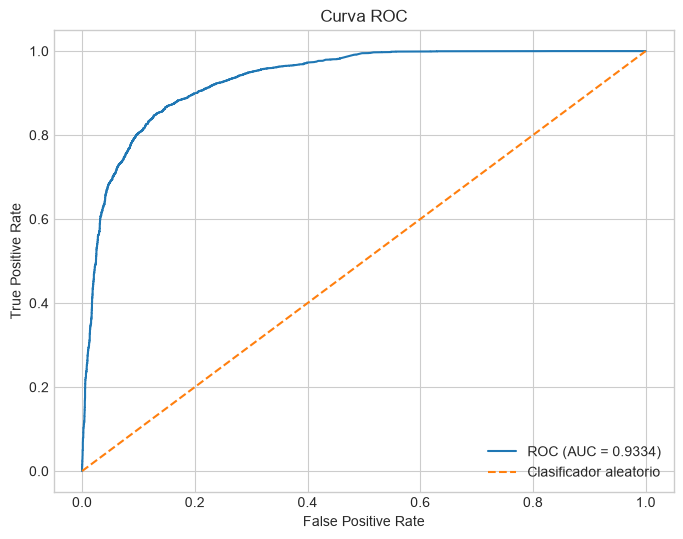

In [9]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba_test)

roc_auc = roc_auc_score(y_test, y_proba_test)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'ROC (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Clasificador aleatorio'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.grid(True)

plt.show()

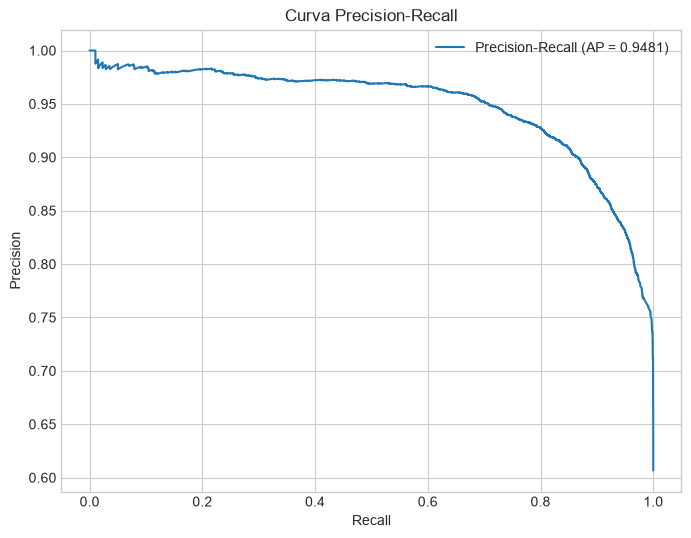

In [10]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_proba_test
)

ap = average_precision_score(
    y_test,
    y_proba_test
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'Precision-Recall (AP = {ap:.4f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')
plt.legend()
plt.grid(True)

plt.show()